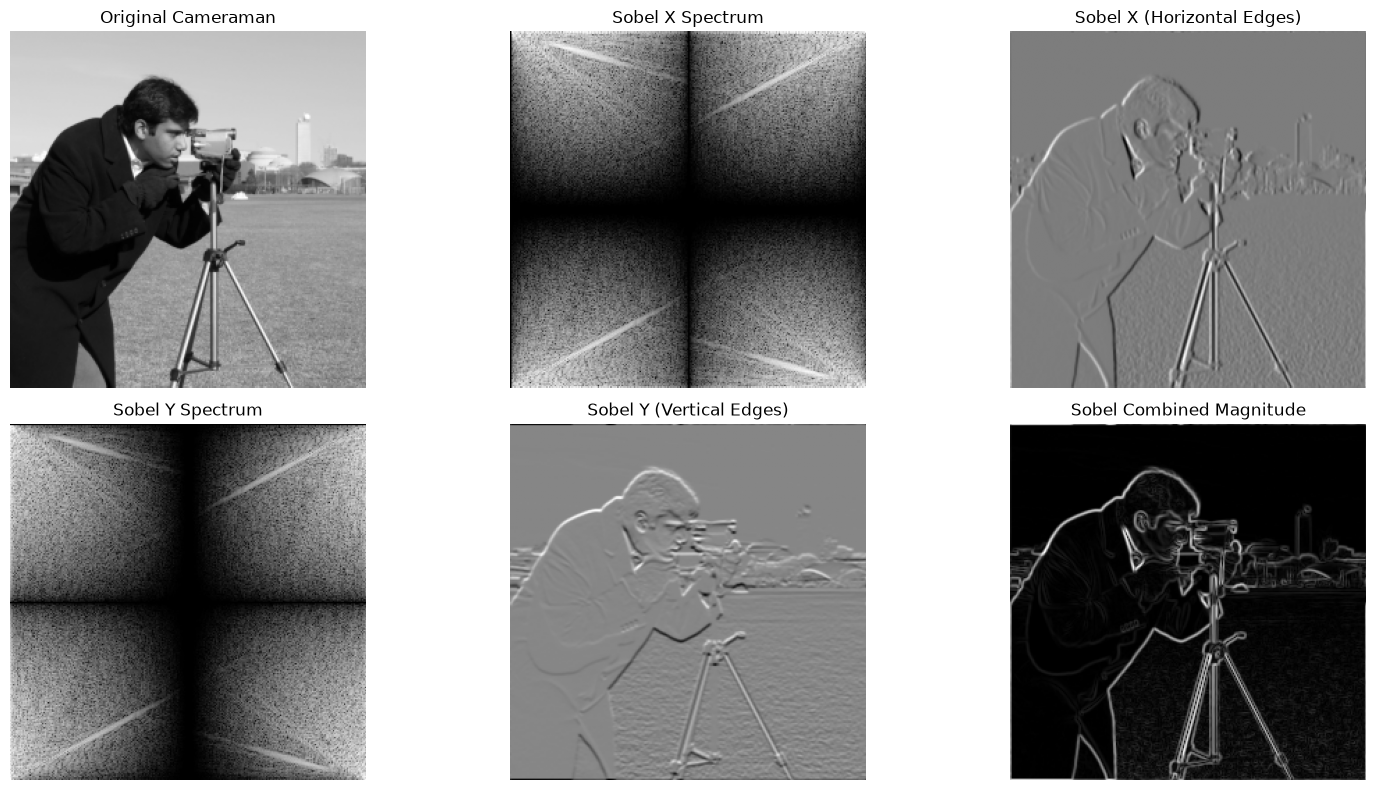

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from numpy.fft import fft2, ifft2, ifftshift


image = data.camera()
image = resize(image, (256, 256))
image_shape = image.shape


sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])


def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy - kh//2 : cy - kh//2 + kh, cx - kw//2 : cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))


F_img = fft2(image)


H_x = center_embed_kernel(sobel_x, image_shape)
H_y = center_embed_kernel(sobel_y, image_shape)


G_x = F_img * H_x
G_y = F_img * H_y


sobel_x_output = ifft2(G_x).real
sobel_y_output = ifft2(G_y).real


sobel_combined = np.sqrt(sobel_x_output**2 + sobel_y_output**2)


plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(np.log(1 + np.abs(G_x)), cmap='gray')
plt.title('Sobel X Spectrum')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(sobel_x_output, cmap='gray')
plt.title('Sobel X (Horizontal Edges)')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(np.log(1 + np.abs(G_y)), cmap='gray')
plt.title('Sobel Y Spectrum')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(sobel_y_output, cmap='gray')
plt.title('Sobel Y (Vertical Edges)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(sobel_combined, cmap='gray')
plt.title('Sobel Combined Magnitude')
plt.axis('off')

plt.tight_layout()
plt.show()